# 01 데이터 파악

서울시 상권분석서비스의 세 데이터(추정매출, 점포, 영역)를 처음 열어 보고, 분석에 앞서 알아야 할 것을 확인한다.

1. 파일 구조: 행·열 수, 분기, 키 중복
2. 커피-음료 업종
3. 매출이 공개되는 조건
4. 서울 전체 카페 손님의 계절성
5. 상권별 데이터 단절
6. 전처리에서 고칠 것

원자료는 `data/raw`에 있고 인코딩은 cp949다. 금액(`당월_매출_금액`)과 건수(`당월_매출_건수`)는 **그 분기의 월평균**이다(원천부서 확인).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

RAW = Path("../data/raw")
코드_열 = {"기준_년분기_코드": str, "상권_코드": str, "자치구_코드": str, "행정동_코드": str}


def 합치기(패턴, 이름_바꾸기=None):
    조각 = []
    for 경로 in sorted(RAW.glob(패턴)):
        df = pd.read_csv(경로, encoding="cp949", dtype=코드_열)
        print(경로.name, df.shape)
        if 이름_바꾸기:
            df = df.rename(columns=이름_바꾸기)
        조각.append(df)
    return pd.concat(조각, ignore_index=True)


매출 = 합치기("*추정매출*.csv")
# 2021~2024년 파일과 2025~2026년 파일의 점포 열 이름이 다르다. 새 이름으로 맞춘다(3절에서 정의가 같음을 확인).
점포 = 합치기("*점포-상권*.csv", {"점포_수": "일반_점포_수", "유사_업종_점포_수": "전체_점포_수"})
영역 = pd.read_csv(RAW / "서울시_상권분석서비스(영역-상권).csv", encoding="cp949", dtype=코드_열)

서울시_상권분석서비스(추정매출-상권)_2021년.csv (89150, 55)


서울시_상권분석서비스(추정매출-상권)_2022년.csv (88834, 55)


서울시_상권분석서비스(추정매출-상권)_2023년.csv (88246, 55)


서울시_상권분석서비스(추정매출-상권)_2024년.csv (87179, 55)


서울시_상권분석서비스(추정매출-상권)_2025~2026년.csv (128053, 55)


서울시_상권분석서비스(점포-상권)_2021년.csv (303880, 14)


서울시_상권분석서비스(점포-상권)_2022년.csv (305587, 14)


서울시_상권분석서비스(점포-상권)_2023년.csv (307741, 14)


서울시_상권분석서비스(점포-상권)_2024년.csv (306889, 14)


서울시_상권분석서비스(점포-상권)_2025~2026년.csv (456659, 14)


## 1. 파일 구조

In [2]:
키 = ["기준_년분기_코드", "상권_코드", "서비스_업종_코드"]
pd.DataFrame({
    "행": [len(매출), len(점포), len(영역)],
    "열": [매출.shape[1], 점포.shape[1], 영역.shape[1]],
    "분기 수": [매출["기준_년분기_코드"].nunique(), 점포["기준_년분기_코드"].nunique(), np.nan],
    "상권 수": [매출["상권_코드"].nunique(), 점포["상권_코드"].nunique(), 영역["상권_코드"].nunique()],
    "업종 수": [매출["서비스_업종_코드"].nunique(), 점포["서비스_업종_코드"].nunique(), np.nan],
    "키 중복": [매출.duplicated(키).sum(), 점포.duplicated(키).sum(), 영역.duplicated("상권_코드").sum()],
    "빈 값": [매출.isna().sum().sum(), 점포.isna().sum().sum(), 영역.isna().sum().sum()],
}, index=["추정매출", "점포", "영역"])

,행,열,분기 수,상권 수,업종 수,키 중복,빈 값
추정매출,481462,55,22.0,1598,63.0,0,0
점포,1680756,14,22.0,1650,100.0,0,0
영역,1650,11,NaN,1650,NaN,0,0


In [3]:
print("분기:", 매출["기준_년분기_코드"].min(), "~", 매출["기준_년분기_코드"].max())
# 점포 열 이름을 바꾼 것이 맞는지: 22개 분기 모두 일반 + 프랜차이즈 = 전체가 성립하는가
print("일반 + 프랜차이즈 ≠ 전체인 행:", int((점포["일반_점포_수"] + 점포["프랜차이즈_점포_수"] != 점포["전체_점포_수"]).sum()))
# 매출·점포의 상권이 모두 영역에 있는가
print("영역에 없는 상권: 매출", len(set(매출["상권_코드"]) - set(영역["상권_코드"])),
      "/ 점포", len(set(점포["상권_코드"]) - set(영역["상권_코드"])))
영역["상권_구분_코드_명"].value_counts()

분기: 20211 ~ 20262
일반 + 프랜차이즈 ≠ 전체인 행: 0
영역에 없는 상권: 매출 0 / 점포 0


상권_구분_코드_명
골목상권    1090
전통시장     305
발달상권     249
관광특구       6
Name: count, dtype: int64

## 2. 커피-음료 업종

업종 코드 `CS100010`이 커피-음료다. 이후 분석은 이 업종만 쓴다.

In [4]:
커피_코드 = "CS100010"
print(매출.loc[매출["서비스_업종_코드"] == 커피_코드, "서비스_업종_코드_명"].unique())
커피_매출 = 매출[매출["서비스_업종_코드"] == 커피_코드]
커피_점포 = 점포[점포["서비스_업종_코드"] == 커피_코드]
print("커피 매출", len(커피_매출), "행 / 커피 점포", len(커피_점포), "행")
pd.DataFrame({
    "매출이 있는 상권": 커피_매출.groupby("기준_년분기_코드")["상권_코드"].nunique(),
    "점포가 있는 상권": 커피_점포[커피_점포["전체_점포_수"] > 0].groupby("기준_년분기_코드")["상권_코드"].nunique(),
    "서울 카페 점포 수": 커피_점포.groupby("기준_년분기_코드")["전체_점포_수"].sum(),
}).T

['커피-음료']


커피 매출 23700 행 / 커피 점포 33263 행


기준_년분기_코드,20211,20212,20213,20214,20221,20222,20223,20224,20231,20232,...,20241,20242,20243,20244,20251,20252,20253,20254,20261,20262
매출이 있는 상권,1047,1057,1067,1072,1070,1073,1083,1092,1085,1097,...,1087,1084,1088,1089,1077,1073,1077,1069,1064,1064
점포가 있는 상권,1480,1485,1493,1496,1496,1503,1504,1504,1503,1507,...,1519,1524,1523,1523,1521,1515,1515,1516,1512,1509
서울 카페 점포 수,19569,20017,20394,21014,21356,22057,22228,22918,22983,23266,...,23450,23409,23232,23042,22834,22707,22505,22356,22233,22229


## 3. 매출이 공개되는 조건

카페가 있는데 매출이 없는 상권이 분기마다 약 450개 있다. 매출이 있는 상권의 최소 점포 수를 보면 이유가 보인다.

In [5]:
연결 = 커피_점포.merge(커피_매출[["기준_년분기_코드", "상권_코드", "당월_매출_금액"]],
                    on=["기준_년분기_코드", "상권_코드"], how="left", validate="one_to_one")
매출_있음 = 연결["당월_매출_금액"].notna()
print("매출이 있는 상권의 최소 점포 수(분기별):", sorted(연결[매출_있음].groupby("기준_년분기_코드")["전체_점포_수"].min().unique()))

최근 = 연결[연결["기준_년분기_코드"] == "20262"]
최근 = 최근[최근["전체_점포_수"] > 0]
pd.crosstab(pd.cut(최근["전체_점포_수"], [0, 2, 9, 1000], labels=["1~2개", "3~9개", "10개 이상"]),
            최근["당월_매출_금액"].notna().map({True: "매출 있음", False: "매출 없음"}))

매출이 있는 상권의 최소 점포 수(분기별): [np.int64(3)]


당월_매출_금액,매출 없음,매출 있음
전체_점포_수,,
1~2개,286,0
3~9개,142,490
10개 이상,17,574


**정리**: 22개 분기 모두 매출이 있는 상권의 최소 점포 수는 정확히 3개다. 카페가 1~2개인 상권은 매출이 공개되지 않는다. 그래서 이 분석은 **매출이 공개된 상권 안에서의 추천**이다. 점포가 3개 이상인데도 매출이 없는 상권도 있으므로(원인은 공개되지 않음), 한계에 적는다.

## 4. 서울 전체 카페 손님의 계절성

22개 분기 모두 커피 매출이 있는 상권을 합쳐 분기별 손님(결제 건수)을 본다. 상권이 들고 나는 효과를 없애기 위해 같은 상권만 쓴다.

In [6]:
건수_표 = 커피_매출.pivot(index="상권_코드", columns="기준_년분기_코드", values="당월_매출_건수")
전체_분기 = 건수_표.dropna().index
서울 = pd.DataFrame({"건수(만 건)": 건수_표.loc[전체_분기].sum() / 1e4})
서울["전 분기 대비(%)"] = 서울["건수(만 건)"].pct_change() * 100
서울["전년 같은 분기 대비(%)"] = 서울["건수(만 건)"].pct_change(4) * 100
print(len(전체_분기), "개 상권 합계")
서울.round(1).T

916 개 상권 합계


기준_년분기_코드,20211,20212,20213,20214,20221,20222,20223,20224,20231,20232,...,20241,20242,20243,20244,20251,20252,20253,20254,20261,20262
건수(만 건),6176.0,8190.3,8061.7,8151.6,7016.5,8960.4,9031.2,8532.9,8052.6,9058.1,...,7964.9,9445.8,9178.7,8540.5,7598.2,8969.6,9287.2,8233.5,7670.3,9091.9
전 분기 대비(%),NaN,32.6,-1.6,1.1,-13.9,27.7,0.8,-5.5,-5.6,12.5,...,-5.7,18.6,-2.8,-7.0,-11.0,18.0,3.5,-11.3,-6.8,18.5
전년 같은 분기 대비(%),NaN,NaN,NaN,NaN,13.6,9.4,12.0,4.7,14.8,1.1,...,-1.1,4.3,1.3,1.1,-4.6,-5.0,1.2,-3.6,0.9,1.4


분기별 전 분기 대비 중앙값(%): {'1': -6.8, '2': 18.6, '3': -0.0, '4': -6.7}


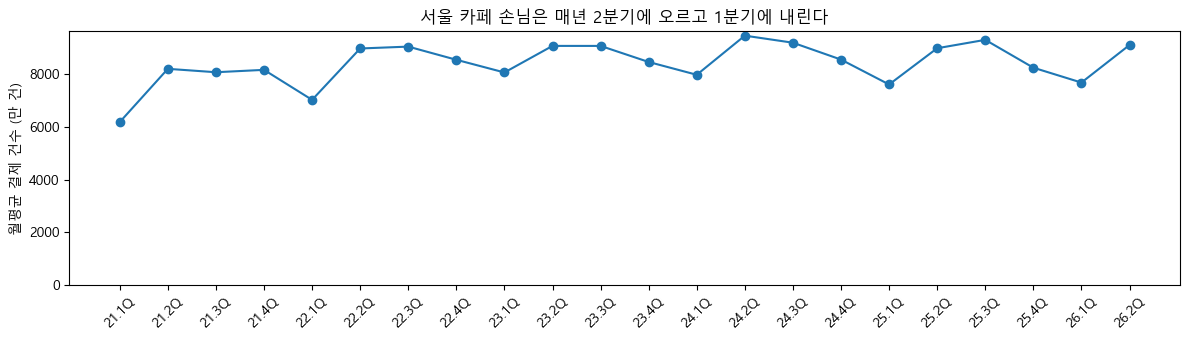

In [7]:
분기별 = 서울["전 분기 대비(%)"].groupby(서울.index.str[-1]).median()
print("분기별 전 분기 대비 중앙값(%):", 분기별.round(1).to_dict())

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot([f"{q[2:4]}.{q[4]}Q" for q in 서울.index], 서울["건수(만 건)"], marker="o")
ax.set_ylim(bottom=0)
ax.set_ylabel("월평균 결제 건수 (만 건)")
ax.set_title("서울 카페 손님은 매년 2분기에 오르고 1분기에 내린다")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

**정리**: 매년 2분기에 손님이 크게 늘고(+17~18% 안팎) 1분기에 줄어든다. 바로 앞 분기와 비교하면 이 계절 효과를 상권의 변화로 잘못 읽는다. 그래서 이후 지표는 **4개 분기 합계끼리** 또는 **전년 같은 분기끼리** 비교한다. 서울 전체로는 2023년 이후 손님이 거의 그대로이고 카페 수는 2024년 1분기부터 줄고 있다.

## 5. 상권별 데이터 단절

한 분기 만에 손님이 2배 넘게 뛰거나 절반 아래로 떨어지는 상권이 있다. 계절 효과(+18% 안팎)로는 설명되지 않는 크기라 추계 방식의 변화나 데이터 단절일 가능성이 크다.

In [8]:
분기_변화 = 건수_표.pct_change(axis=1, fill_method=None).iloc[:, 1:]
pd.DataFrame({
    "2배 넘게 뜀": (분기_변화 > 1.0).sum(),
    "절반 아래로 떨어짐": (분기_변화 < -0.5).sum(),
}).T

기준_년분기_코드,20212,20213,20214,20221,20222,20223,20224,20231,20232,20233,...,20241,20242,20243,20244,20251,20252,20253,20254,20261,20262
2배 넘게 뜀,52,27,14,12,44,27,14,22,41,21,...,23,37,14,8,12,26,21,10,12,26
절반 아래로 떨어짐,5,11,17,26,13,19,15,28,8,16,...,16,10,27,22,26,11,20,11,14,15


In [9]:
# 예: 사당역 4번(3110902)
예 = "3110902"
print(영역.set_index("상권_코드").at[예, "상권_코드_명"])
(건수_표.loc[예, "20231":"20244"] / 1e4).round(1)

사당역 4번


기준_년분기_코드
20231     2.1
20232     2.1
20233     2.1
20234     1.8
20241     9.9
20242    11.7
20243    11.7
20244    10.3
Name: 3110902, dtype: float64

**정리**: 이런 상권은 증가율이 부풀거나 꺼지므로, 추천에서는 **최근 12개 분기 안에 단절이 있는 상권을 뺀다**(지표 정의서).

## 6. 전처리에서 고칠 것

In [10]:
print("상권 이름에 '?'가 들어간 행(영역):", int(영역["상권_코드_명"].str.contains("?", regex=False).sum()))
print("행정동 이름에 '?'가 들어간 행(영역):", int(영역["행정동_코드_명"].str.contains("?", regex=False).sum()))
print("이름이 2개 이상인 상권 코드(매출):", int((매출.groupby("상권_코드")["상권_코드_명"].nunique() > 1).sum()))
print("깨진 시간대 건수 열 이름:", [열 for 열 in 매출.columns if 열.startswith("시간대_건수")])
print("실수형으로 읽힌 금액 열:", len(커피_매출.select_dtypes("float").columns))

상권 이름에 '?'가 들어간 행(영역): 1
행정동 이름에 '?'가 들어간 행(영역): 38
이름이 2개 이상인 상권 코드(매출): 3
깨진 시간대 건수 열 이름: ['시간대_건수~06_매출_건수', '시간대_건수~11_매출_건수', '시간대_건수~14_매출_건수', '시간대_건수~17_매출_건수', '시간대_건수~21_매출_건수', '시간대_건수~24_매출_건수']
실수형으로 읽힌 금액 열: 22


| 무엇 | 처리 |
|---|---|
| 가운뎃점(·)이 `?`로 깨짐 (예: `종로?청계 관광특구`) | `?`를 `·`로 바꾼다. 같은 상권의 앞 연도 이름에 `종로·청계`가 있어 가운뎃점임이 확인된다 |
| 상권 코드 하나에 이름이 둘 | 이름은 영역 표를 기준으로 통일한다. 연결은 코드로 한다 |
| 시간대별 건수 열 이름 6개가 `시간대_건수~06_매출_건수`처럼 깨짐 | 금액 열과 같은 규칙(`시간대_00~06_매출_건수`)으로 바꾼다 |
| 점포 열 이름이 2025년부터 바뀜 | 새 이름(`전체_점포_수`, `일반_점포_수`)으로 통일한다 |
| 금액 열 일부가 실수형 | 소수 부분이 모두 0이므로 정수로 바꾼다. 21억을 넘으므로 SQL에서는 `BIGINT` |
| 다른 업종 | 커피-음료(`CS100010`)만 남긴다 |